# Détection d'une figure : du simulateur à l'entraînement
Dataset synthétique → apprentissage → feature maps → prédiction + NMS.

In [ ]:
import os, random
import numpy as np
import torch
from PIL import Image
from torch.utils.data import DataLoader, TensorDataset

os.chdir(os.path.dirname(os.path.abspath("")) if os.path.basename(os.path.abspath("")) == "notebooks" else ".")

from src.dataset_generator_3 import make_example
from src.detector import Detector, STRIDE, ANCHORS, RATIO_MAX, predict, code
from src.visualize import show_images, show_feature_maps, show_detections
from src.train import evaluate, train

MODEL_SIZE = 64
assert MODEL_SIZE % STRIDE == 0

# L'ancre unique de l'ancien TP, gardée pour la comparaison finale
BASELINE_ANCHORS = ((1.0, 1.0),)

## 1. Génération du dataset
On génère directement les images à la taille attendue par le modèle.

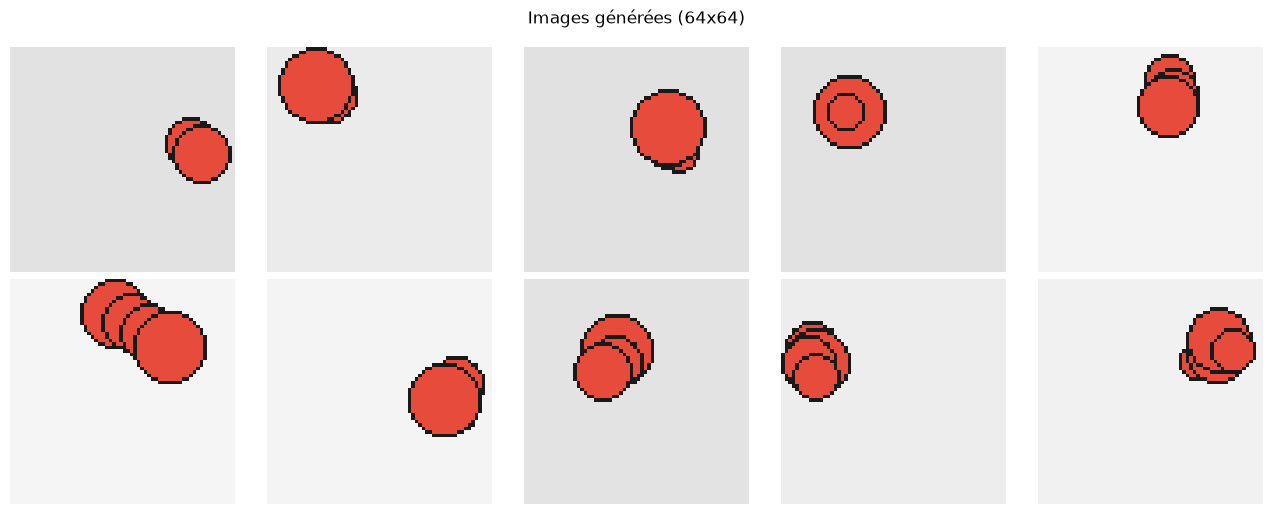

In [16]:
rng = random.Random(123)

# On demande entre 2 et 4 objets pour illustrer la limite des superpositions
pil_images = [make_example(MODEL_SIZE, "circle", rng, min_objects=2, max_objects=4)[0] for _ in range(10)]
show_images(pil_images, f"Images générées ({MODEL_SIZE}x{MODEL_SIZE})")

Les images sont déjà générées à la taille attendue par le détecteur (`MODEL_SIZE`×`MODEL_SIZE`, multiple du stride) : aucun redimensionnement, on les convertit simplement en tenseurs `(3, H, W)` normalisés dans [0, 1].

In [ ]:
def to_tensor(image):
    return torch.from_numpy(np.asarray(image.convert("RGB"), dtype=np.float32).copy()).permute(2, 0, 1) / 255.0

def parse_labels(label):
    """Sépare le texte brut pour récupérer les coordonnées de TOUS les cercles."""
    return [tuple(map(float, line.split())) for line in label.splitlines()]

def make_dataset(count, seed, anchors):
    rng = random.Random(seed)
    dataset_images, targets = [], []
    for _ in range(count):
        image, label = make_example(MODEL_SIZE, "circle", rng, 2, 4)
        dataset_images.append(to_tensor(image))
        # On envoie la liste des cercles à notre fonction code()
        targets.append(code(parse_labels(label), size=MODEL_SIZE, anchors=anchors))
        
    return TensorDataset(torch.stack(dataset_images), torch.stack(targets))

# test pour s'assurer que le tenseur a bien gonflé à 15 canaux
dummy_dataset = make_dataset(count=2, seed=42, anchors=ANCHORS)
print("Dimension des images :", dummy_dataset[0][0].shape)
print("Dimension des cibles (K*5) :", dummy_dataset[0][1].shape)

Dimension des images : torch.Size([3, 64, 64])
Dimension des cibles (K*5) : torch.Size([15, 8, 8])


## 2. Génération d'un jeu de données d'entraînement plus grand
On génère 2 000 images pour l'entraînement et 400 images indépendantes pour la validation. Les étiquettes (en pixels) sont encodées en cibles `(5, G, G)`.
## 3. Entraînement du modèle



Logs TensorBoard : C:\Users\UTILIS~1\AppData\Local\Temp\tb_runs\demo
--- 1/2 : Entraînement du modèle de base (K=1) ---
[initial_K1] epoch  1  loss 0.0150  val IoU 0.344  rappel 17%  précision 6%
[initial_K1] epoch  2  loss 0.0078  val IoU 0.631  rappel 83%  précision 64%
[initial_K1] epoch  3  loss 0.0054  val IoU 0.637  rappel 79%  précision 72%
[initial_K1] epoch  4  loss 0.0043  val IoU 0.650  rappel 92%  précision 70%
[initial_K1] epoch  5  loss 0.0039  val IoU 0.682  rappel 92%  précision 70%
[initial_K1] epoch  6  loss 0.0036  val IoU 0.692  rappel 87%  précision 81%
[initial_K1] epoch  7  loss 0.0035  val IoU 0.702  rappel 92%  précision 73%
[initial_K1] epoch  8  loss 0.0034  val IoU 0.697  rappel 90%  précision 78%
[initial_K1] epoch  9  loss 0.0033  val IoU 0.704  rappel 93%  précision 73%
[initial_K1] epoch 10  loss 0.0033  val IoU 0.701  rappel 91%  précision 77%
[initial_K1] epoch 11  loss 0.0032  val IoU 0.689  rappel 91%  précision 69%
[initial_K1] epoch 12  loss 0.0031

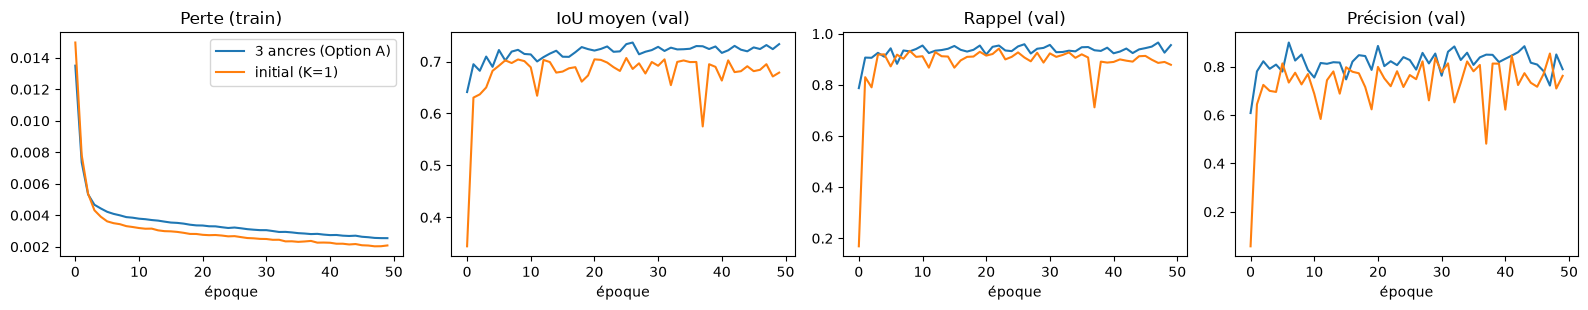

In [14]:
# --- Paramètres d'entraînement ---
TRAIN_SAMPLES = 2000
VAL_SAMPLES = 400
BATCH_SIZE = 64
EPOCHS = 50
LR = 3e-3

import tempfile
import matplotlib.pyplot as plt
from datetime import datetime
from pathlib import Path
from torch.utils.tensorboard import SummaryWriter

LOG_ROOT = Path(tempfile.gettempdir()) / "tb_runs" / "demo"
LOG_ROOT.mkdir(parents=True, exist_ok=True)
print("Logs TensorBoard :", LOG_ROOT)

def fit(name, anchors):
    torch.manual_seed(0)
    train_loader = DataLoader(make_dataset(TRAIN_SAMPLES, seed=7, anchors=anchors), batch_size=BATCH_SIZE, shuffle=True)
    val_loader = DataLoader(make_dataset(VAL_SAMPLES, seed=8, anchors=anchors), batch_size=BATCH_SIZE)

    model = Detector(anchors)
    optimizer = torch.optim.Adam(model.parameters(), lr=LR)
    history = {"loss": [], "mean_iou": [], "recall": [], "precision": []}
    
    run_dir = LOG_ROOT / f"{name}-{datetime.now().strftime('%Y%m%d-%H%M%S')}"
    with SummaryWriter(log_dir=str(run_dir)) as writer:
        for epoch in range(1, EPOCHS + 1):
            mean_loss = train(model, train_loader, optimizer)
            m = evaluate(model, val_loader, MODEL_SIZE)
            
            for key, value in (("loss", mean_loss), ("mean_iou", m["mean_iou"]),
                               ("recall", m["recall"]), ("precision", m["precision"])):
                history[key].append(value)
            
            # Affichage à CHAQUE époque
            print(f"[{name}] epoch {epoch:2d}  loss {mean_loss:.4f}  val IoU {m['mean_iou']:.3f}  "
                  f"rappel {m['recall']:.0%}  précision {m['precision']:.0%}")
            
    model.eval()
    return model, history

print("--- 1/2 : Entraînement du modèle de base (K=1) ---")
model_base, history_base = fit("initial_K1", BASELINE_ANCHORS)

print("\n--- 2/2 : Entraînement du modèle Option A (K=3) ---")
model_k3, history_k3 = fit("ancres_K3", ANCHORS)

# On trace nos courbes comparatives à la toute fin
fig, axes = plt.subplots(1, 4, figsize=(16, 3.2))
for ax, key, title in zip(axes, ("loss", "mean_iou", "recall", "precision"),
                          ("Perte (train)", "IoU moyen (val)", "Rappel (val)", "Précision (val)")):
    ax.plot(history_k3[key], label="3 ancres (Option A)")
    ax.plot(history_base[key], label="initial (K=1)")
    ax.set_title(title); ax.set_xlabel("époque")
axes[0].legend()
fig.tight_layout()
plt.show()

In [6]:
# Affiche la commande à lancer dans un terminal pour ouvrir TensorBoard dans le navigateur
import sys
print(f'& "{sys.executable}" -m tensorboard.main --logdir "{LOG_ROOT}" --port 6006')
print("Puis ouvrir http://localhost:6006")

& "c:\Users\Utilisateur\Downloads\sujet_tensorboard (1)\.venv\Scripts\python.exe" -m tensorboard.main --logdir "C:\Users\UTILIS~1\AppData\Local\Temp\tb_runs\demo" --port 6006
Puis ouvrir http://localhost:6006


## 4. Feature maps

Dimension des feature maps : torch.Size([10, 32, 8, 8])


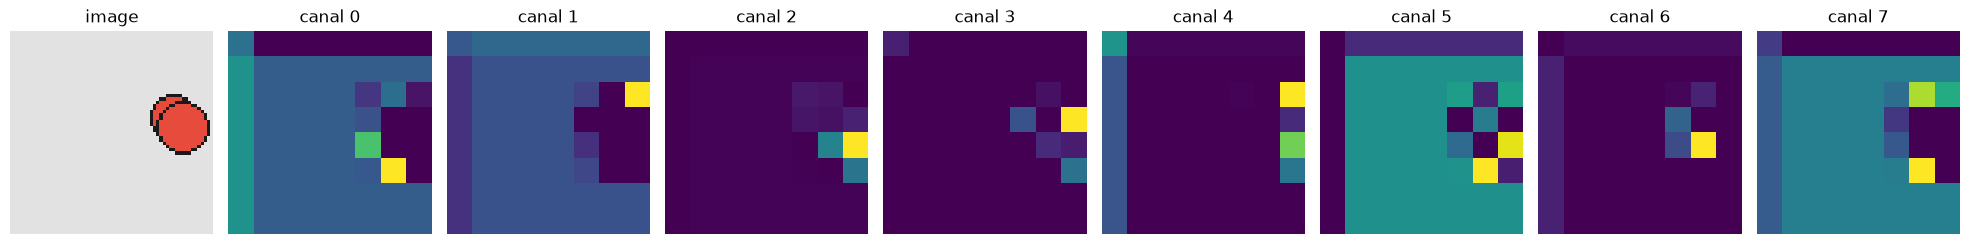

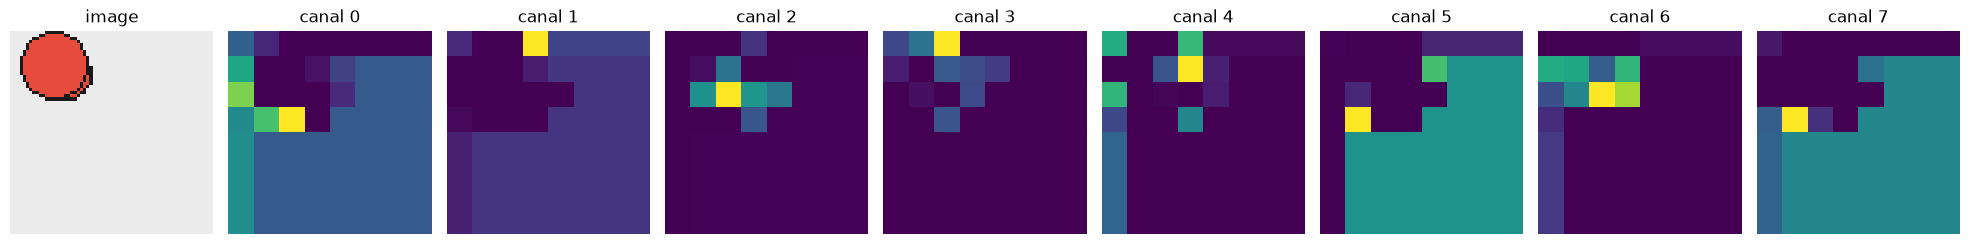

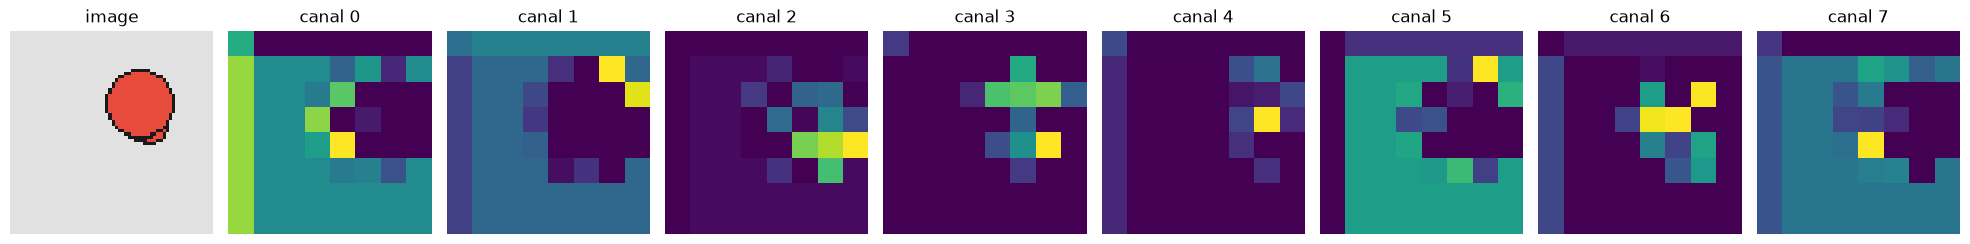

In [7]:
images = torch.stack([to_tensor(im) for im in pil_images])

with torch.no_grad():
    maps = model_k3.feature_maps(images)   # Sortie : (N, 32, 8, 8)

print("Dimension des feature maps :", maps.shape)

# On affiche les 8 premiers canaux de la feature map pour 3 images
for i in range(3):
    show_feature_maps(images[i], maps[i], n_maps=8)

## 5. Prédiction, décodage et NMS : une boîte par image

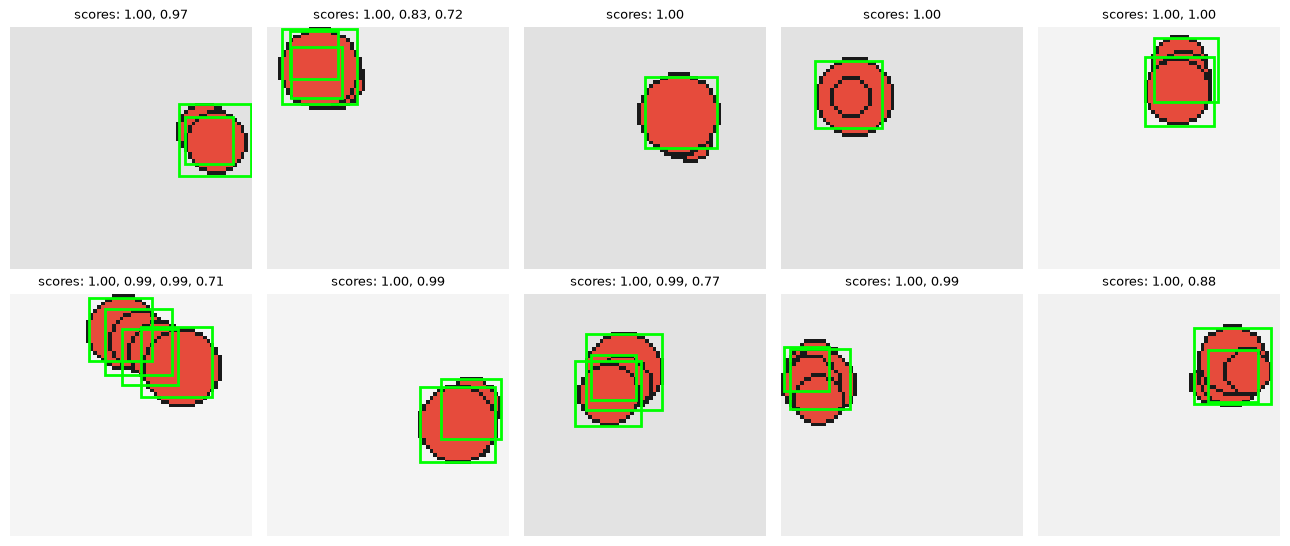

In [13]:
with torch.no_grad():
    logits = model_k3(images)

# Application du seuil de confiance (0.7) et du NMS corrigé (0.7) pour tolérer les collisions
# Un score exigeant (0.85) et un NMS rééquilibré (0.45)
results = [predict(l, MODEL_SIZE, model_k3.anchors, score_threshold=0.7, iou_threshold=0.45) for l in logits]

show_detections(list(images), [b for b, _ in results], [s for _, s in results])

## 5. Cartes d'objectness de chaque ancre
Visualisation de l'endroit où chaque ancre "voit" une figure. On remarque comment les ancres se répartissent les objets superposés.

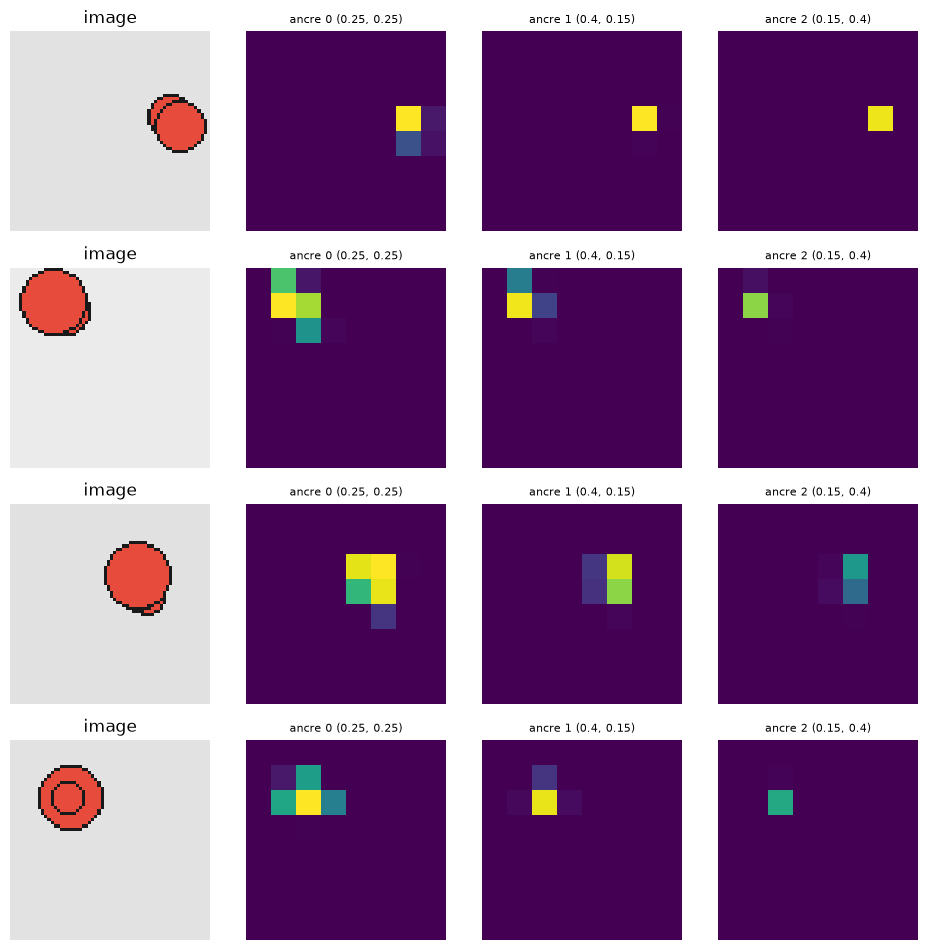

In [17]:
import matplotlib.pyplot as plt

# On extrait les prédictions brutes pour les 4 premières images
with torch.no_grad():
    logits_sample = model_k3(images[:4])                       
    
# On isole uniquement le canal 0 (la probabilité de présence) pour nos 3 ancres
objectness = torch.sigmoid(logits_sample.reshape(4, len(ANCHORS), 5, 8, 8)[:, :, 0])

fig, axes = plt.subplots(4, len(ANCHORS) + 1, figsize=(2.4 * (len(ANCHORS) + 1), 9.6))
for i in range(4):
    axes[i, 0].imshow(images[i].permute(1, 2, 0))
    axes[i, 0].set_title("image")
    for k, (aw, ah) in enumerate(ANCHORS):
        axes[i, k + 1].imshow(objectness[i, k], vmin=0, vmax=1, cmap="viridis")
        axes[i, k + 1].set_title(f"ancre {k} ({aw}, {ah})", fontsize=8)
        
for ax in axes.flat: 
    ax.axis("off")
fig.tight_layout()
plt.show()